TASK 1: EXPLORATORY DATA ANALYSIS ON RETAIL SALES DATA

Objective: Identify sales patterns, customer behaviour, product performance and actionable insights.

Import the necessary packages and load the data

In [1]:
%pip install seaborn -q

import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

# Visualisation configuration
sns.set_theme(style="whitegrid", palette="deep")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("Libraries imported successfully.")
print("Retail Sales EDA environment is ready.")

Libraries imported successfully.
Retail Sales EDA environment is ready.


1.0 Load the dataset

In [2]:
from pathlib import Path

data_folder = Path("../data")


file_path = data_folder / "retail_sales_dataset.csv"
df = pd.read_csv(file_path)

Inspect the Dataset

In [3]:
print("Dataset Shape:", df.shape)
print("Number of Records:", df.shape[0])
print("Number of Variables:", df.shape[1])

Dataset Shape: (1000, 9)
Number of Records: 1000
Number of Variables: 9


In [4]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


In [5]:
display(df.head())

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [6]:
display(df.dtypes.to_frame(name="Data Type"))

,Data Type
Transaction ID,int64
Date,object
Customer ID,object
Gender,object
Age,int64
Product Category,object
Quantity,int64
Price per Unit,int64
Total Amount,int64


Checking the missing values

In [7]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})
display(missing_values)

,Missing Count,Missing Percentage
Transaction ID,0,0.0
Date,0,0.0
Customer ID,0,0.0
Gender,0,0.0
Age,0,0.0
Product Category,0,0.0
Quantity,0,0.0
Price per Unit,0,0.0
Total Amount,0,0.0


Checking the duplicate records

In [8]:
print("\nDuplicate Records:", df.duplicated().sum())


Duplicate Records: 0


1.0 Initial Dataset Inspection

The retail sales dataset contains 1,000 transaction records and 9 variables. The initial inspection revealed that the dataset has no missing values and no duplicate records, indicating good completeness at this stage of the analysis.

The variables cover transaction information, customer demographics and sales performance. The dataset includes customer age and gender, product categories, quantities purchased, unit prices and total transaction amounts.

Most variables have appropriate data types. However, the Date column is currently stored as an object rather than a datetime variable. This will be corrected before conducting time-series analysis.

Overall, the dataset provides a suitable foundation for investigating sales trends, customer demographics and product performance.

2.0 Descriptive Stastistics

In [9]:
numerical_columns = df.select_dtypes(include=np.number).columns

2.1 Calculation of descriptive statistics for the numerical variables

In [10]:
descriptive_stats = pd.DataFrame({
    "Mean": df[numerical_columns].mean(),
    "Median": df[numerical_columns].median(),
    "Mode": df[numerical_columns].mode().iloc[0],
    "Standard Deviation": df[numerical_columns].std()
})

descriptive_stats = descriptive_stats.round(2)
display(descriptive_stats)

,Mean,Median,Mode,Standard Deviation
Transaction ID,500.50,500.5,1.0,288.82
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00


2.0 Descriptive Statistics – Observations

The descriptive statistics show that the average customer age is approximately 41 years, with a median age of 42 years. This indicates that the dataset contains a customer base concentrated around middle adulthood.

The average purchase quantity is 2.51 units, while the most frequently occurring quantity is 4 units. This provides an initial indication of customer purchasing behaviour.

The average unit price is 179.89, compared with a median of 50. Similarly, the average transaction amount is 456, compared with a median of 135. These differences suggest that higher-value purchases may be influencing the averages.

The findings indicate variation in transaction values and product prices. Further visual analysis will help establish the distribution and patterns behind these differences.

3.0 Time Series Analysis

3.1 Preparation of the date variable and calculation of sales

In [11]:
# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Check for invalid dates
print("Invalid dates:", df["Date"].isnull().sum())

# Display date range
print("First transaction date:", df["Date"].min())
print("Last transaction date:", df["Date"].max())

# Set Date as the index for time-based aggregation
sales_by_date = df.set_index("Date").sort_index()

Invalid dates: 0
First transaction date: 2023-01-01 00:00:00
Last transaction date: 2024-01-01 00:00:00


In [12]:
monthly_sales = sales_by_date["Total Amount"].resample("MS").sum()

quarterly_sales = sales_by_date["Total Amount"].resample("QS").sum()

print("\nMonthly Sales:")
display(monthly_sales.to_frame(name="Total Sales"))

print("\nQuarterly Sales:")
display(quarterly_sales.to_frame(name="Total Sales"))


Monthly Sales:


,Total Sales
Date,
2023-01-01,35450
2023-02-01,44060
2023-03-01,28990
2023-04-01,33870
2023-05-01,53150
2023-06-01,36715
2023-07-01,35465
2023-08-01,36960
2023-09-01,23620



Quarterly Sales:


,Total Sales
Date,
2023-01-01,108500
2023-04-01,123735
2023-07-01,96045
2023-10-01,126190
2024-01-01,1530


January 2024 investigations

In [13]:
monthly_transactions = (
    df.set_index("Date")
      .resample("MS")
      .size()
)

monthly_summary = pd.DataFrame({
    "Number of Transactions": monthly_transactions,
    "Total Sales": monthly_sales
})

display(monthly_summary)

january_2024 = df[
    (df["Date"] >= "2024-01-01") &
    (df["Date"] < "2024-02-01")
]

print("January 2024 transaction records:")
display(january_2024)

print("Total January 2024 transactions:", len(january_2024))

,Number of Transactions,Total Sales
Date,,
2023-01-01,76,35450
2023-02-01,85,44060
2023-03-01,73,28990
2023-04-01,86,33870
2023-05-01,105,53150
2023-06-01,77,36715
2023-07-01,72,35465
2023-08-01,94,36960
2023-09-01,65,23620


January 2024 transaction records:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
210,211,2024-01-01,CUST211,Male,42,Beauty,3,500,1500
649,650,2024-01-01,CUST650,Male,55,Electronics,1,30,30


Total January 2024 transactions: 2


3.2 Monthly sales trends

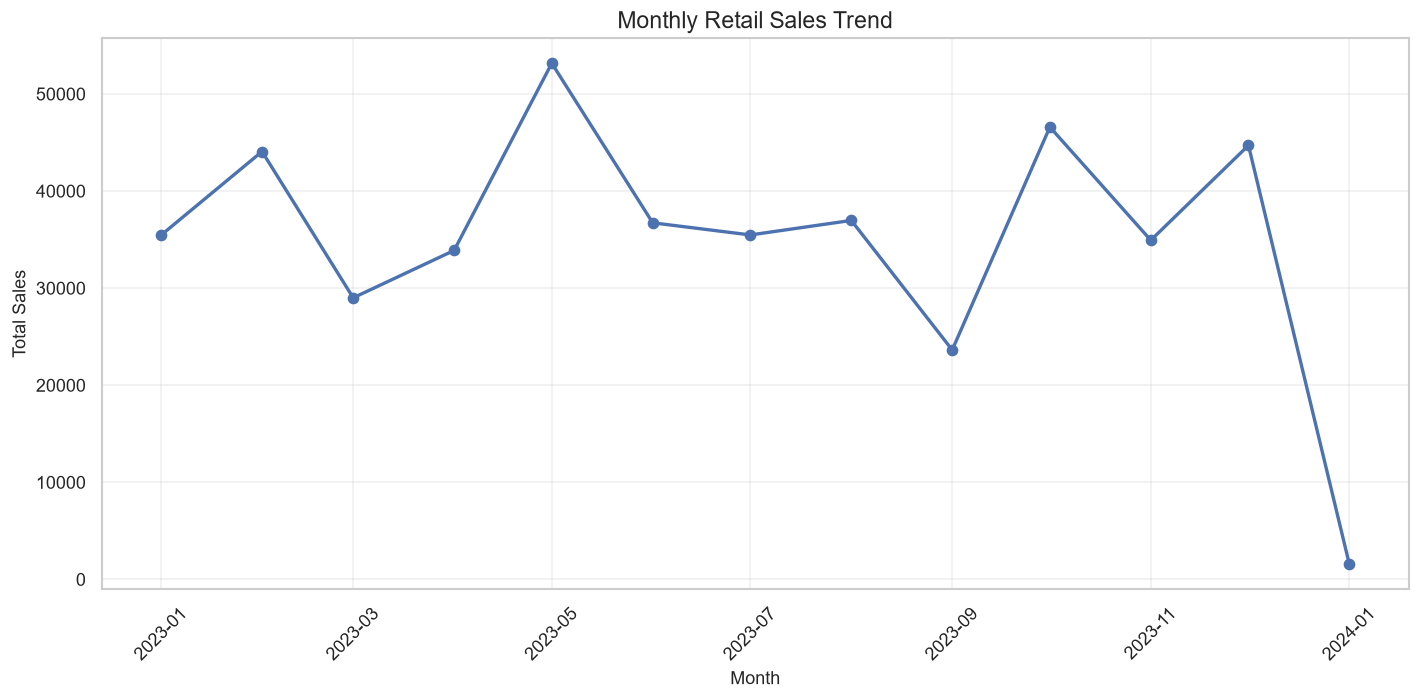

In [14]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

3.1 Monthly Sales Trend – Observations

The monthly sales analysis reveals fluctuations in retail sales throughout 2023. May recorded the highest monthly sales of 53,150, followed by October with 46,580 and February with 44,060.

September recorded the lowest monthly sales in 2023, amounting to 23,620. This indicates variations in monthly sales performance that may warrant further investigation.

January 2024 recorded sales of only 1,530 from two transactions. Since this represents an incomplete reporting period, it should not be interpreted as a genuine decline in business performance.

Overall, the monthly trend highlights fluctuations in sales activity, with May emerging as the strongest month in 2023.

3.3 Quartely Sales trends

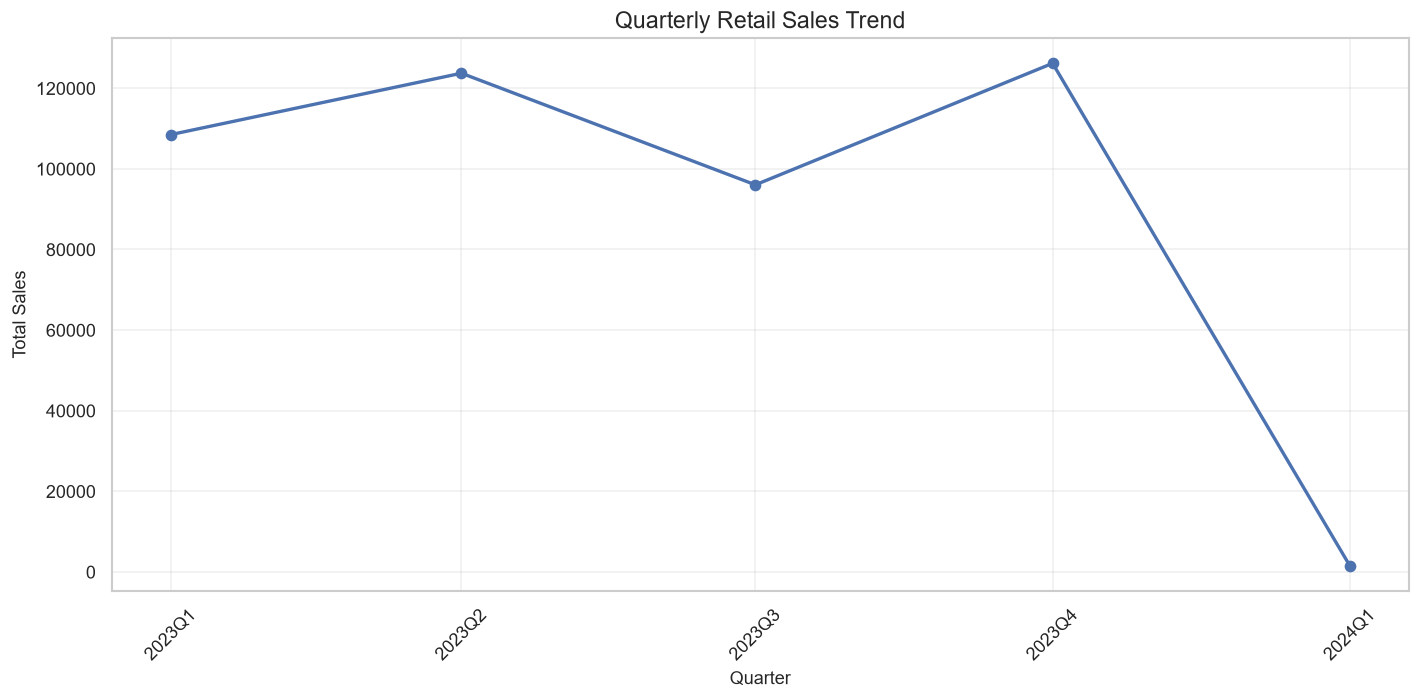

In [15]:
plt.figure(figsize=(12, 6))

plt.plot(
    quarterly_sales.index,
    quarterly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Quarterly Retail Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(
    quarterly_sales.index,
    quarterly_sales.index.to_period("Q").astype(str),
    rotation=45
)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

3.2 Quarterly Sales Trend – Observations

The quarterly analysis shows that the fourth quarter of 2023 recorded the highest sales, amounting to 126,190. The second quarter followed with 123,735, while the first quarter recorded 108,500.

The third quarter recorded the lowest sales of 96,045, indicating relatively weaker performance between July and September.

The first quarter of 2024 recorded only 1,530 because the dataset contains just two transactions for January. This is an incomplete quarter and should be excluded from comparisons with the full quarters of 2023.

Overall, the fourth quarter was the strongest sales period in 2023, suggesting that the business may benefit from investigating customer demand and sales opportunities during the final quarter of the year.

4.0 Customer demographics analysis

4.1 Creation of age groups and examination of their distribution

In [16]:
age_bins = [0, 29, 44, 59, float("inf")]

age_labels = [
    "Young Adults (18-29)",
    "Adults (30-44)",
    "Middle-aged Adults (45-59)",
    "Seniors (60+)"
]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)


age_distribution = df["Age Group"].value_counts().sort_index()

print("CUSTOMER AGE GROUP DISTRIBUTION")
display(
    age_distribution.to_frame(name="Number of Customers")
)

CUSTOMER AGE GROUP DISTRIBUTION


,Number of Customers
Age Group,
Young Adults (18-29),251
Adults (30-44),308
Middle-aged Adults (45-59),326
Seniors (60+),115


Age group visualization

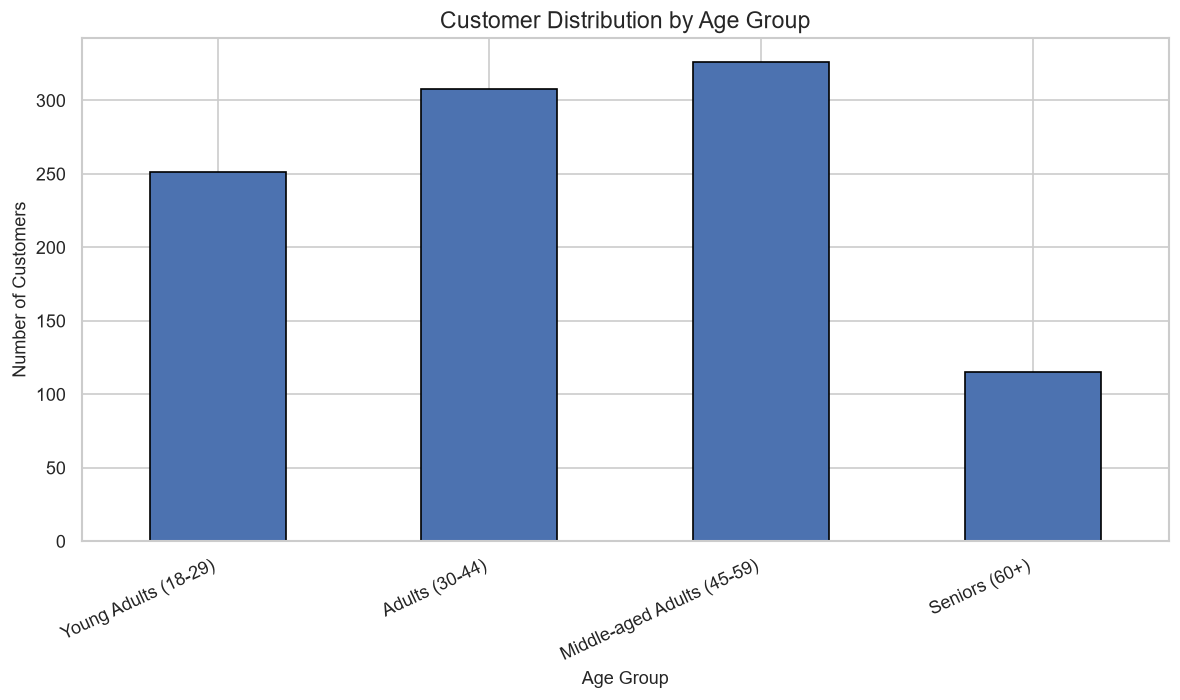

In [17]:
plt.figure(figsize=(10, 6))

age_distribution.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

4.1 Customer Age Group Distribution – Observations

The age distribution shows that middle-aged adults aged 45–59 represent the largest customer segment, accounting for 326 customers (32.6%). Adults aged 30–44 follow with 308 customers (30.8%).

Young adults aged 18–29 account for 251 customers (25.1%), while seniors aged 60 and above represent the smallest segment, with 115 customers (11.5%).

The findings indicate that customers aged 30–59 collectively account for 63.4% of the transactions represented in the dataset. This suggests that the business has a relatively strong customer base among adults in these age groups.

The business could investigate products and marketing strategies that appeal to this customer segment while also exploring opportunities to increase engagement among senior customers.

4.2 Gender distributions

In [18]:
gender_distribution = df["Gender"].value_counts()

gender_percentage = (
    df["Gender"].value_counts(normalize=True) * 100
).round(2)

gender_summary = pd.DataFrame({
    "Number of Customers": gender_distribution,
    "Percentage (%)": gender_percentage
})

print("CUSTOMER GENDER DISTRIBUTION")
display(gender_summary)

CUSTOMER GENDER DISTRIBUTION


,Number of Customers,Percentage (%)
Gender,,
Female,510,51.0
Male,490,49.0


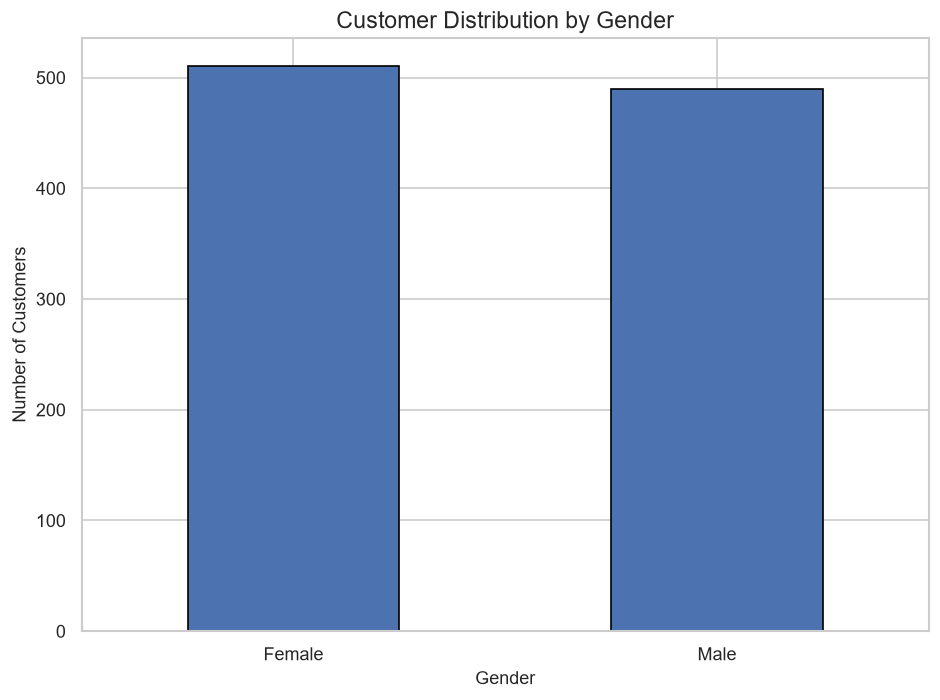

In [19]:
plt.figure(figsize=(8, 6))

gender_distribution.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

4.2 Customer Gender Distribution – Observations

The gender distribution indicates that female customers account for 510 transactions (51%), while male customers account for 490 transactions (49%).

The difference between the two groups is relatively small, suggesting that the retail business attracts customers from both genders at almost equal proportions.

This finding suggests that the business should maintain inclusive marketing strategies rather than concentrating exclusively on one gender. Further analysis of purchasing patterns by gender could help identify whether particular product categories appeal more strongly to either group.

5.0 Product Analysis

5.1 Analyse product category sale

In [20]:
category_quantity = (
    df.groupby("Product Category", observed=False)["Quantity"]
      .sum()
      .sort_values(ascending=False)
)

print("PRODUCT CATEGORIES RANKED BY QUANTITY SOLD")
display(
    category_quantity.to_frame(name="Total Quantity Sold")
)


top_10_categories = category_quantity.head(10)

print("\nTOP 10 BEST-SELLING CATEGORIES")
display(
    top_10_categories.to_frame(name="Quantity Sold")
)

PRODUCT CATEGORIES RANKED BY QUANTITY SOLD


,Total Quantity Sold
Product Category,
Clothing,894
Electronics,849
Beauty,771



TOP 10 BEST-SELLING CATEGORIES


,Quantity Sold
Product Category,
Clothing,894
Electronics,849
Beauty,771


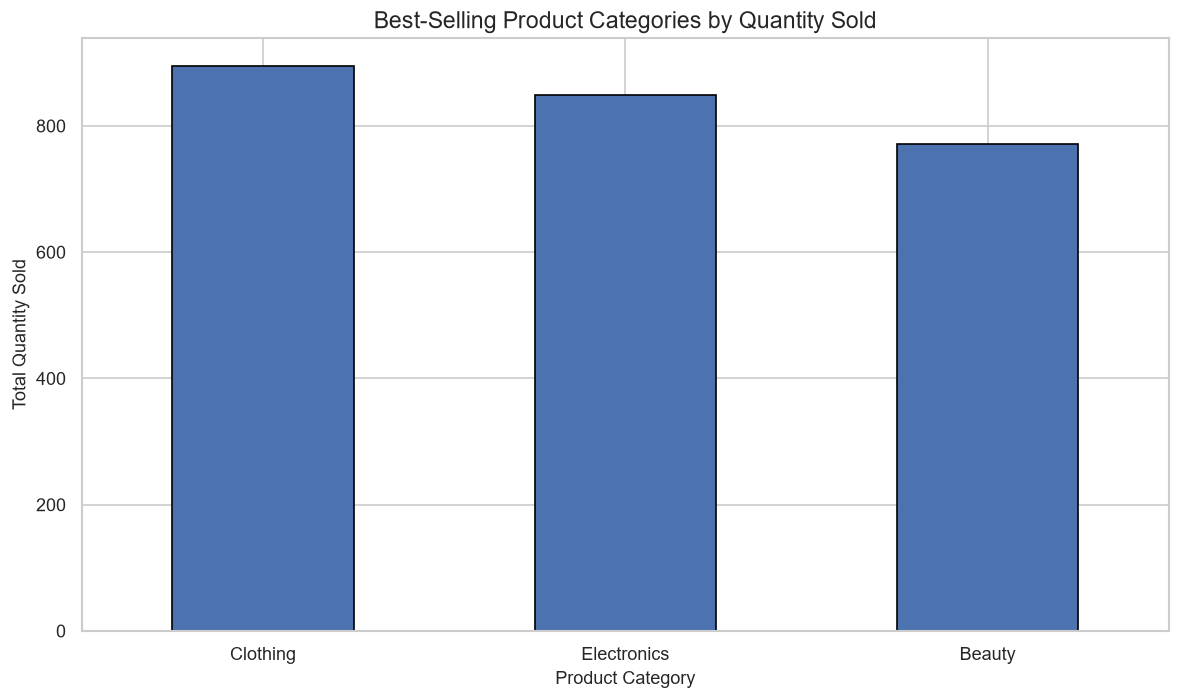

In [21]:
plt.figure(figsize=(10, 6))

top_10_categories.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Best-Selling Product Categories by Quantity Sold")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

5.1 Product Category Performance – Observations

The product analysis indicates that Clothing is the best-performing category by quantity sold, with 894 units. Electronics follows with 849 units, while Beauty records 771 units.

The three categories account for a combined 2,514 units sold across the 1,000 transactions.

Clothing represents the highest sales volume, suggesting stronger demand in terms of units purchased. However, quantity sold alone does not establish which category generates the most revenue. Revenue analysis is therefore necessary to obtain a more complete understanding of product performance.

The dataset contains only three product categories and does not provide individual product names. Consequently, the analysis ranks the available categories rather than individual products.

5.2 Revenue by product category

In [22]:
category_revenue = (
    df.groupby("Product Category", observed=False)["Total Amount"]
      .sum()
      .sort_values(ascending=False)
)

revenue_summary = pd.DataFrame({
    "Total Revenue": category_revenue,
    "Revenue Percentage": (
        category_revenue / category_revenue.sum() * 100
    ).round(2)
})

print("REVENUE BY PRODUCT CATEGORY")
display(revenue_summary)

REVENUE BY PRODUCT CATEGORY


,Total Revenue,Revenue Percentage
Product Category,,
Electronics,156905,34.41
Clothing,155580,34.12
Beauty,143515,31.47


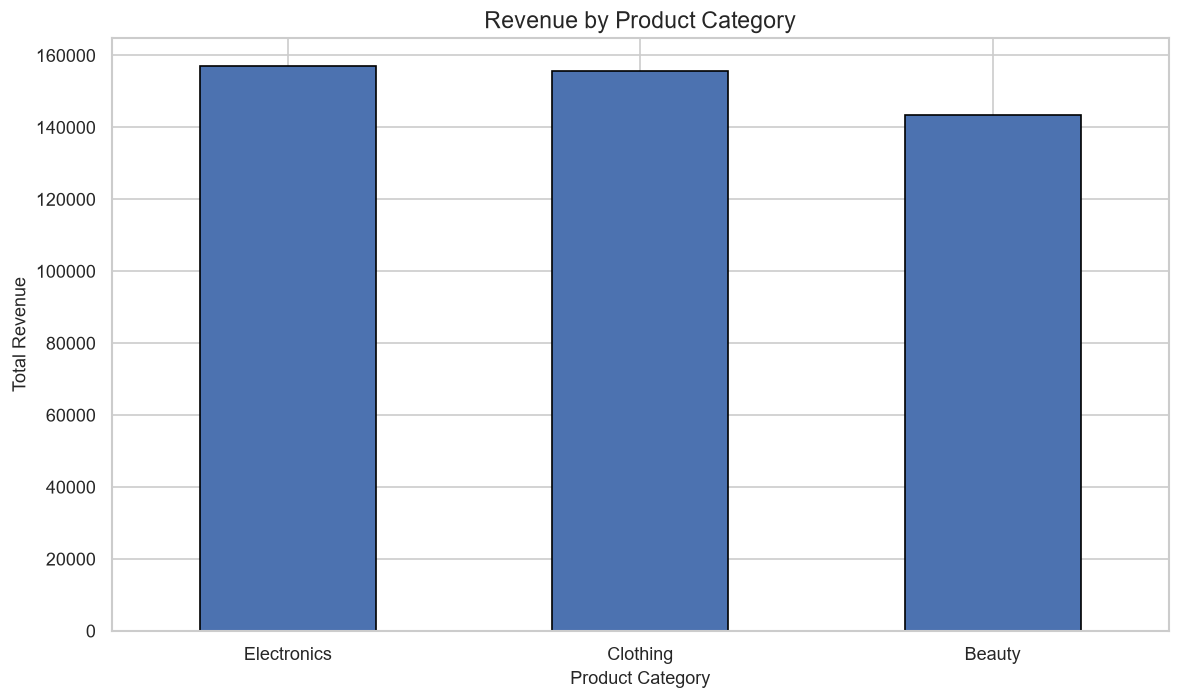

In [23]:
plt.figure(figsize=(10, 6))

category_revenue.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

5.2 Revenue by Product Category – Observations

The revenue analysis shows that Electronics generates the highest revenue, amounting to 156,905 (34.41% of total revenue). Clothing follows closely with 155,580 (34.12%), while Beauty contributes 143,515 (31.47%).

An interesting finding is that Clothing records the highest quantity sold, with 894 units, whereas Electronics generates the highest revenue despite selling 849 units.

This indicates that higher sales volume does not necessarily translate into higher revenue. The business should therefore consider both sales volume and revenue when evaluating product category performance.

Electronics and Clothing are the leading revenue contributors, although the differences between the three categories are relatively small.

6.0 Correlation Heatmap

CORRELATION MATRIX


,Age,Quantity,Price per Unit,Total Amount
Age,1.00,-0.02,-0.04,-0.06
Quantity,-0.02,1.00,0.02,0.37
Price per Unit,-0.04,0.02,1.00,0.85
Total Amount,-0.06,0.37,0.85,1.00


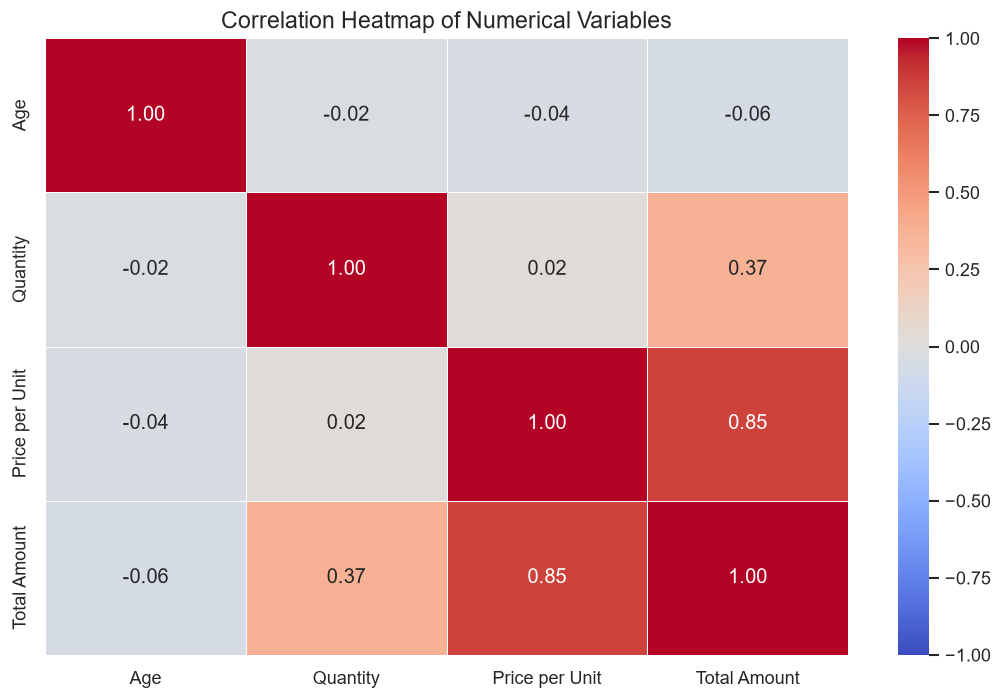

In [24]:
correlation_columns = [
    "Age",
    "Quantity",
    "Price per Unit",
    "Total Amount"
]


correlation_matrix = df[correlation_columns].corr()

print("CORRELATION MATRIX")
display(correlation_matrix.round(2))


plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

6.1 Correlation Heatmap – Observations

The correlation analysis reveals a strong positive relationship between Price per Unit and Total Amount, with a correlation coefficient of 0.85. This indicates that transactions involving higher-priced products tend to have higher total values.

Quantity and Total Amount have a moderate positive correlation of 0.37, suggesting that purchasing more units is also associated with higher transaction values.

Age has very weak negative correlations with Quantity (-0.02) and Total Amount (-0.06). This suggests that customer age has little linear association with purchasing quantity and transaction value in this dataset.

Overall, product pricing has the strongest linear association with transaction value, followed by purchase quantity. These findings highlight the importance of pricing and purchasing behaviour in understanding retail sales performance. Correlation does not, however, establish causation.

7.0 Average transaction value by age group

In [25]:
age_group_spending = (
    df.groupby("Age Group", observed=False)["Total Amount"]
      .mean()
      .sort_values(ascending=False)
)

print("AVERAGE TRANSACTION VALUE BY AGE GROUP")

display(
    age_group_spending
    .round(2)
    .to_frame(name="Average Transaction Value")
)

AVERAGE TRANSACTION VALUE BY AGE GROUP


,Average Transaction Value
Age Group,
Young Adults (18-29),490.66
Adults (30-44),472.14
Middle-aged Adults (45-59),437.45
Seniors (60+),389.70


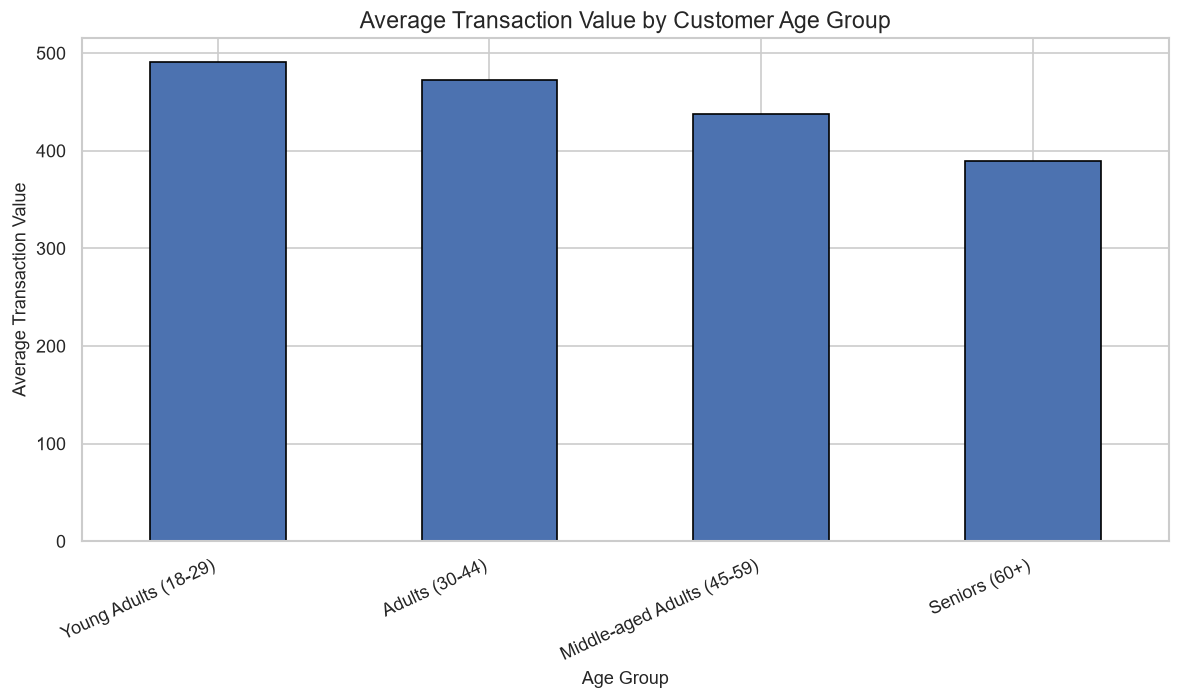

In [26]:
plt.figure(figsize=(10, 6))

age_group_spending.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Average Transaction Value by Customer Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Transaction Value")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

7.1 Observations:

The analysis reveals that Young Adults (18–29) have the highest average transaction value of 490.66, followed by Adults (30–44) at 472.14. Middle-aged Adults (45–59) record an average transaction value of 437.45, while Seniors (60+) have the lowest average of 389.70.

An interesting finding is that the largest age group, Middle-aged Adults (45–59), does not generate the highest average transaction value per transaction. Instead, Young Adults demonstrate higher average spending per transaction. This suggests that the business could investigate purchasing preferences across age groups and develop targeted marketing strategies. However, these results describe transaction values and do not establish the reasons behind the spending differences.

8.0 Conclusion and Business Recommendations

8.1 Conclusion

This exploratory data analysis examined a retail sales dataset containing 1,000 transaction records and nine original variables. The analysis investigated sales trends, customer demographics, product category performance and relationships between numerical variables.

The initial inspection established that the dataset contained no missing values or duplicate records. The time-series analysis showed that May 2023 recorded the highest monthly sales of 53,150, while the fourth quarter of 2023 recorded the highest quarterly sales of 126,190.

The demographic analysis revealed that Middle-aged Adults (45–59) represented the largest age group, accounting for 32.6% of transaction records. Female records accounted for 51%, compared with 49% for males, indicating a relatively balanced gender distribution.

Product category analysis showed that Clothing recorded the highest sales volume at 894 units, while Electronics generated the highest revenue of 156,905, representing 34.41% of total revenue. This demonstrated that the category with the highest quantity sold was not necessarily the category generating the highest revenue.

The correlation analysis identified a strong positive relationship between Price per Unit and Total Amount (0.85), while Quantity and Total Amount had a moderate positive relationship (0.37). The additional analysis revealed that Young Adults (18–29) had the highest average transaction value of 490.66, whereas Seniors (60+) had the lowest at 389.70.

Overall, the analysis identified useful patterns in sales performance and customer purchasing behaviour that can inform retail planning and decision-making.

8.2 Business Recommendations

Based on the findings, the following recommendations are proposed:

1. Strengthen inventory planning around high-performing periods.

May 2023 recorded the highest monthly sales, while the fourth quarter recorded the highest quarterly sales. The business should examine demand patterns during these periods and plan inventory levels, staffing and promotional activities accordingly to reduce stock shortages and improve sales performance.

2. Develop targeted marketing strategies for different age groups.

Young Adults (18–29) recorded the highest average transaction value, while Middle-aged Adults (45–59) represented the largest age group. The business should develop targeted promotions that encourage repeat purchases among younger customers while maintaining engagement with the larger middle-aged customer segment.

3. Prioritise revenue-generating product categories.

Electronics generated the highest revenue, while Clothing recorded the highest quantity sold. Management should monitor category-level revenue and sales volumes when making inventory and promotional decisions. Strategies should consider both sales volume and revenue rather than relying on quantity sold alone.

4. Investigate opportunities to increase average transaction value among senior customers.

Seniors (60+) recorded the lowest average transaction value of 389.70. The business could investigate their purchasing preferences and test suitable product bundles, loyalty incentives and targeted promotions to encourage additional purchases.

5. Improve the quality and detail of retail sales data.

The dataset contains product categories but does not identify individual products. The business should capture product names or stock-keeping unit (SKU) codes in future transaction records. This would enable more detailed product-level analysis, including identification of the top ten individual products. Recording product costs would also support profitability analysis.

8.3 Final Remarks

This project demonstrates how exploratory data analysis can transform raw retail transaction records into meaningful business insights. Through descriptive statistics, time-series analysis, demographic analysis, product performance analysis and data visualisation, the analysis provides a foundation for evidence-based retail decision-making.

The findings are limited to the available dataset and should be interpreted within its scope. In particular, January 2024 contains only two transactions, making it an incomplete period for comparison with the full months of 2023. Furthermore, the dataset does not contain individual product names or product cost information, limiting product-level and profitability analysis.